DEN702 — FINAL PUBLICATION FIGURES AND TABLES

Project root:
/Users/am/Documents/ADU/wifi-localization-research

All frozen results loaded successfully.

TABLE 1 — DATASET CHARACTERISTICS


,Characteristic,Value
0,Training fingerprints,19937.00
1,Official validation/test fingerprints,1111.00
2,Wi-Fi access-point features,520.00
3,Buildings,3.00
4,Floors,5.00
5,Building-floor classes,13.00
6,Undetected AP values (%),96.54



TABLE 2 — CLEAN CLASSIFICATION BASELINES


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,KNN,0.9915,0.9890,0.9915,0.9902
1,Random Forest,0.9965,0.9951,0.9967,0.9959
2,MLP,0.9932,0.9917,0.9935,0.9925



TABLE 3 — CLEAN LOCALIZATION BASELINES


...

,Task,Condition,Baseline,Robust,Improvement,95% CI
0,Classification,Clean,0.9109,0.9055,-0.0054,"[-0.0180, 0.0063]"
1,Classification,50% AP Loss + sigma=10,0.6853,0.7424,0.0571,"[0.0441, 0.0706]"
2,Localization,Clean,12.0538,10.1136,1.9402,"[1.4704, 2.4083]"
3,Localization,50% AP Loss + sigma=10,30.1632,15.2405,14.9227,"[14.2087, 15.6291]"



TABLE 5 — CLASSIFICATION ACROSS 24 CONDITIONS


,Training Regime,Mean Accuracy,Mean Macro F1,Minimum Accuracy,Maximum Accuracy
0,AP Dropout,0.8483,0.8361,0.7424,0.9055
1,Clean,0.8218,0.8085,0.6853,0.9122



TABLE 6 — LOCALIZATION ACROSS 24 CONDITIONS


,Training Regime,Mean Error,Median Condition Error,Minimum Error,Maximum Error
0,Clean,18.5953,16.9085,12.0538,30.1632
1,Combined,11.9318,11.6042,10.1136,15.2405


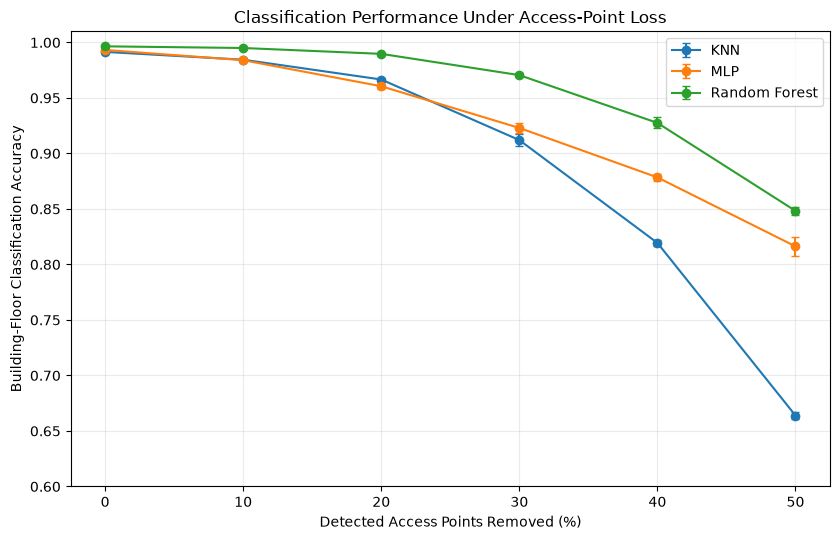

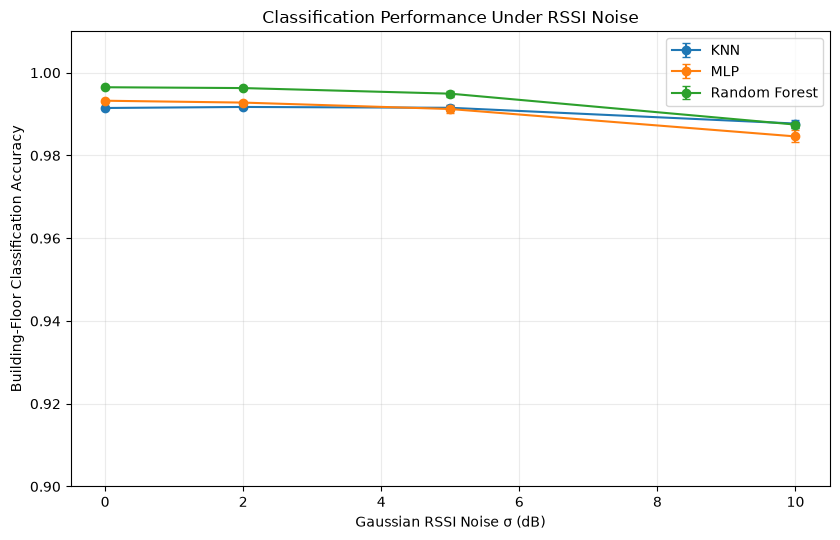

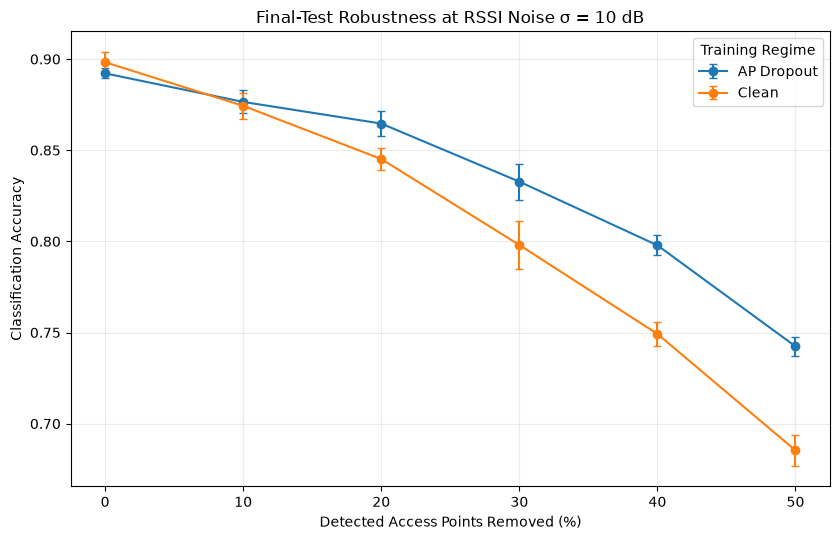

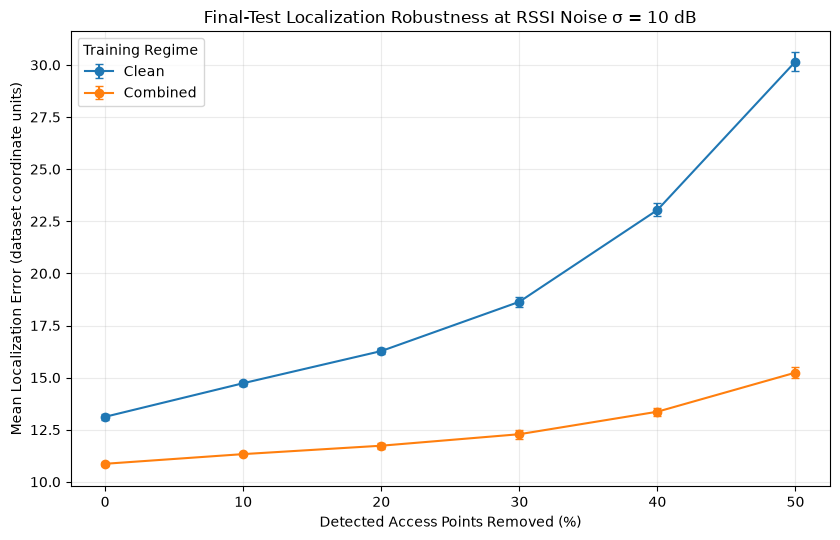

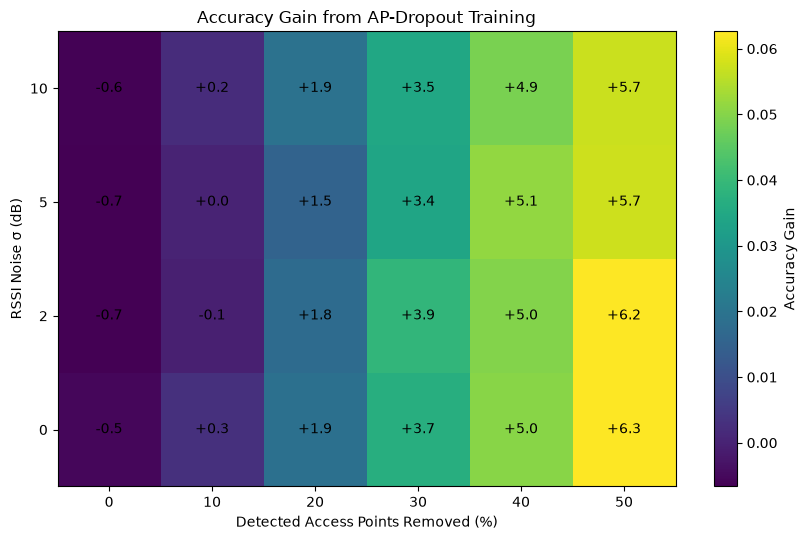

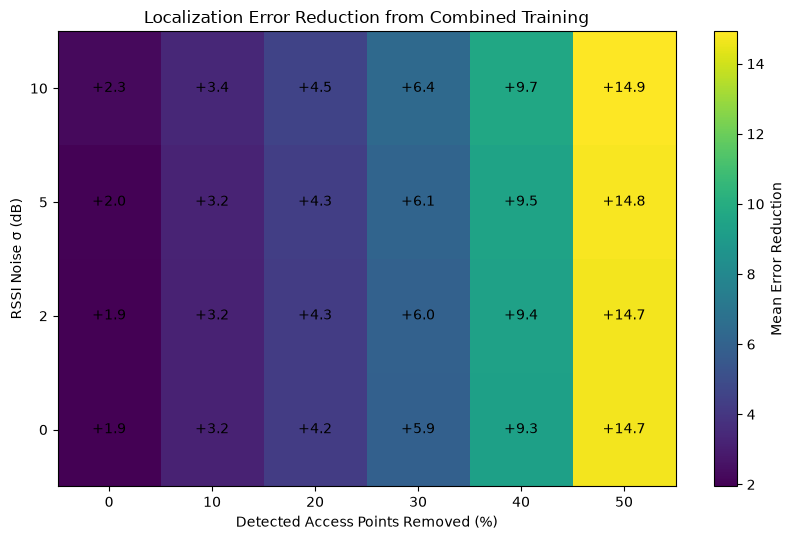

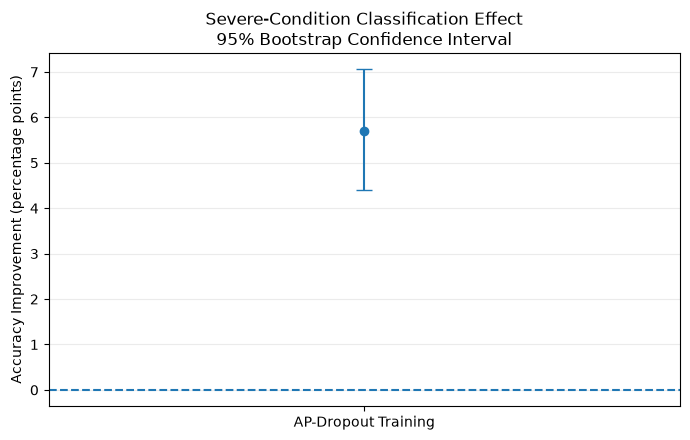

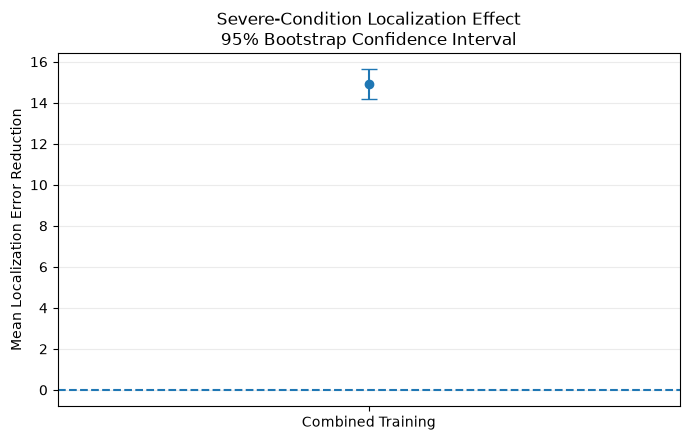


DEN702 FINAL EXPERIMENTAL RESULTS

DATASET
-------
Training fingerprints: 19,937
Held-out final-test fingerprints: 1,111
Wi-Fi access-point features: 520
Building-floor classes: 13
Undetected AP proportion: 96.54%

FINAL CLASSIFICATION
--------------------
Clean condition:
Clean-trained MLP accuracy:
0.9109

AP-dropout-trained MLP accuracy:
0.9055

Difference:
-0.0054

95% bootstrap CI:
[-0.0180,
 0.0063]


Severe condition:
50% detected-AP loss + RSSI noise sigma=10 dB

Clean-trained MLP accuracy:
0.6853

AP-dropout-trained MLP accuracy:
0.7424

Accuracy improvement:
0.0571

Accuracy improvement in percentage points:
5.71

95% bootstrap CI:
[0.0441,
 0.0706]


FINAL LOCALIZATION
------------------
Clean condition:

Clean-trained MLP mean error:
12.0538

Combined-training MLP mean error:
10.1136

Error reduction:
1.9402

95% bootstrap CI:
[1.4704,
 2.4083]


Severe condition:
50% detected-AP loss + RSSI noise sigma=10 dB

Clean-trained MLP mean error:
30.1632

Combined-training MLP me

,Type,File,Purpose
0,Figure,fig_ap_loss_classification.pdf,AP-loss baseline comparison
1,Figure,fig_rssi_noise_classification.pdf,RSSI-noise baseline comparison
2,Figure,fig_final_classification_robustness.pdf,Final classification robustness
3,Figure,fig_final_localization_robustness.pdf,Final localization robustness
4,Figure,fig_accuracy_improvement_heatmap.pdf,Classification improvement heatmap
5,Figure,fig_localization_error_reduction_heatmap.pdf,Localization improvement heatmap
6,Figure,fig_classification_bootstrap_effect.pdf,Classification bootstrap effect
7,Figure,fig_localization_bootstrap_effect.pdf,Localization bootstrap effect
8,Table,table_dataset_characteristics.tex,Dataset characteristics
9,Table,table_clean_classification_baselines.tex,Classification baselines



NOTEBOOK 10 COMPLETED SUCCESSFULLY

FINAL PAPER FIGURES:
- /Users/am/Documents/ADU/wifi-localization-research/paper/figures/fig_ap_loss_classification.pdf
- /Users/am/Documents/ADU/wifi-localization-research/paper/figures/fig_rssi_noise_classification.pdf
- /Users/am/Documents/ADU/wifi-localization-research/paper/figures/fig_final_classification_robustness.pdf
- /Users/am/Documents/ADU/wifi-localization-research/paper/figures/fig_final_localization_robustness.pdf
- /Users/am/Documents/ADU/wifi-localization-research/paper/figures/fig_accuracy_improvement_heatmap.pdf
- /Users/am/Documents/ADU/wifi-localization-research/paper/figures/fig_localization_error_reduction_heatmap.pdf
- /Users/am/Documents/ADU/wifi-localization-research/paper/figures/fig_classification_bootstrap_effect.pdf
- /Users/am/Documents/ADU/wifi-localization-research/paper/figures/fig_localization_bootstrap_effect.pdf

FINAL LATEX TABLES:
- /Users/am/Documents/ADU/wifi-localization-research/paper/tables/table_dataset_ch

In [2]:
# ============================================================
# DEN702 Research Paper
# Notebook 10 — Final Publication Figures and Tables
#
# Research Topic:
# Robust Wi-Fi Fingerprint-Based Indoor Localization
# Under Access-Point Loss and RSSI Noise
#
# PURPOSE:
#
# 1. Load frozen results from Notebooks 01–09
# 2. Generate final publication-quality figures
# 3. Generate compact paper tables
# 4. Export LaTeX tables for Overleaf
# 5. Create a final numerical-results summary
#
# IMPORTANT:
#
# - NO training
# - NO model tuning
# - NO model selection
# - NO modification of final-test results
#
# All values originate from the completed frozen experiments.
# ============================================================


# ------------------------------------------------------------
# Step 1 — Import Required Libraries
# ------------------------------------------------------------

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display


warnings.filterwarnings("ignore")


print("=" * 86)
print("DEN702 — FINAL PUBLICATION FIGURES AND TABLES")
print("=" * 86)


# ------------------------------------------------------------
# Step 2 — Detect Project Root
# ------------------------------------------------------------

if Path("../results/csv/09_statistical_summary.csv").exists():

    PROJECT_ROOT = Path("..").resolve()

elif Path("results/csv/09_statistical_summary.csv").exists():

    PROJECT_ROOT = Path(".").resolve()

else:

    raise FileNotFoundError(
        "Could not locate final statistical result files.\n"
        "Run Notebook 09 before Notebook 10."
    )


RESULTS_CSV_DIR = (
    PROJECT_ROOT
    / "results"
    / "csv"
)


RESULTS_FIGURES_DIR = (
    PROJECT_ROOT
    / "results"
    / "figures"
)


PAPER_DIR = (
    PROJECT_ROOT
    / "paper"
)


PAPER_TABLE_DIR = (
    PAPER_DIR
    / "tables"
)


PAPER_FIGURE_DIR = (
    PAPER_DIR
    / "figures"
)


PAPER_TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


PAPER_FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


print("\nProject root:")
print(PROJECT_ROOT)


# ============================================================
# PART A — LOAD FROZEN RESULTS
# ============================================================


# ------------------------------------------------------------
# Step 3 — Load Dataset Summary
# ------------------------------------------------------------

dataset_summary = pd.read_csv(
    RESULTS_CSV_DIR
    / "01_dataset_summary.csv"
)


preprocessing_summary = pd.read_csv(
    RESULTS_CSV_DIR
    / "02_preprocessing_summary.csv"
)


# ------------------------------------------------------------
# Step 4 — Load Clean Baseline Results
# ------------------------------------------------------------

clean_classification = pd.read_csv(
    RESULTS_CSV_DIR
    / "03_clean_classification_baselines.csv"
)


clean_regression = pd.read_csv(
    RESULTS_CSV_DIR
    / "03_clean_regression_baselines.csv"
)


# ------------------------------------------------------------
# Step 5 — Load AP-Loss Results
# ------------------------------------------------------------

ap_classification = pd.read_csv(
    RESULTS_CSV_DIR
    / "04_ap_loss_classification_summary.csv"
)


ap_regression = pd.read_csv(
    RESULTS_CSV_DIR
    / "04_ap_loss_regression_summary.csv"
)


# ------------------------------------------------------------
# Step 6 — Load RSSI-Noise Results
# ------------------------------------------------------------

noise_classification = pd.read_csv(
    RESULTS_CSV_DIR
    / "05_rssi_noise_classification_summary.csv"
)


noise_regression = pd.read_csv(
    RESULTS_CSV_DIR
    / "05_rssi_noise_regression_summary.csv"
)


# ------------------------------------------------------------
# Step 7 — Load Final Held-Out Test Results
# ------------------------------------------------------------

final_classification = pd.read_csv(
    RESULTS_CSV_DIR
    / "08_final_classification_summary.csv"
)


final_localization = pd.read_csv(
    RESULTS_CSV_DIR
    / "08_final_localization_summary.csv"
)


fullgrid_classification = pd.read_csv(
    RESULTS_CSV_DIR
    / "08_final_fullgrid_classification.csv"
)


fullgrid_localization = pd.read_csv(
    RESULTS_CSV_DIR
    / "08_final_fullgrid_localization.csv"
)


# ------------------------------------------------------------
# Step 8 — Load Statistical Analysis
# ------------------------------------------------------------

statistical_summary = pd.read_csv(
    RESULTS_CSV_DIR
    / "09_statistical_summary.csv"
)


classification_grid_summary = pd.read_csv(
    RESULTS_CSV_DIR
    / "09_classification_grid_summary.csv"
)


localization_grid_summary = pd.read_csv(
    RESULTS_CSV_DIR
    / "09_localization_grid_summary.csv"
)


paper_statistics = pd.read_csv(
    RESULTS_CSV_DIR
    / "09_final_paper_statistical_results.csv"
)


print("\nAll frozen results loaded successfully.")


# ============================================================
# PART B — FINAL DATASET TABLE
# ============================================================


# ------------------------------------------------------------
# Step 9 — Build Compact Dataset Table
# ------------------------------------------------------------

def get_dataset_value(characteristic):

    row = dataset_summary[
        dataset_summary[
            "Characteristic"
        ]
        == characteristic
    ]

    if len(row) == 0:

        return np.nan

    return row[
        "Value"
    ].iloc[0]


dataset_table = pd.DataFrame(
    [
        {
            "Characteristic":
                "Training fingerprints",

            "Value":
                int(
                    float(
                        get_dataset_value(
                            "Training Samples"
                        )
                    )
                )
        },

        {
            "Characteristic":
                "Official validation/test fingerprints",

            "Value":
                int(
                    float(
                        get_dataset_value(
                            "Validation Samples"
                        )
                    )
                )
        },

        {
            "Characteristic":
                "Wi-Fi access-point features",

            "Value":
                int(
                    float(
                        get_dataset_value(
                            "WiFi AP Features"
                        )
                    )
                )
        },

        {
            "Characteristic":
                "Buildings",

            "Value":
                int(
                    float(
                        get_dataset_value(
                            "Buildings"
                        )
                    )
                )
        },

        {
            "Characteristic":
                "Floors",

            "Value":
                int(
                    float(
                        get_dataset_value(
                            "Floors"
                        )
                    )
                )
        },

        {
            "Characteristic":
                "Building-floor classes",

            "Value":
                int(
                    float(
                        get_dataset_value(
                            "Building-Floor Classes"
                        )
                    )
                )
        },

        {
            "Characteristic":
                "Undetected AP values (%)",

            "Value":
                round(
                    float(
                        get_dataset_value(
                            "Undetected AP Percentage"
                        )
                    ),
                    2
                )
        }
    ]
)


print("\n" + "=" * 86)
print("TABLE 1 — DATASET CHARACTERISTICS")
print("=" * 86)


display(
    dataset_table
)


# ============================================================
# PART C — CLEAN BASELINE TABLE
# ============================================================


# ------------------------------------------------------------
# Step 10 — Classification Baseline Table
# ------------------------------------------------------------

classification_baseline_table = (

    clean_classification[
        [
            "Model",
            "Accuracy",
            "Precision_Macro",
            "Recall_Macro",
            "F1_Macro"
        ]
    ]

    .copy()
)


classification_baseline_table.columns = [
    "Model",
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1"
]


print("\n" + "=" * 86)
print("TABLE 2 — CLEAN CLASSIFICATION BASELINES")
print("=" * 86)


display(
    classification_baseline_table.round(4)
)


# ------------------------------------------------------------
# Step 11 — Localization Baseline Table
# ------------------------------------------------------------

localization_baseline_table = (

    clean_regression[
        [
            "Model",
            "Coordinate_MAE",
            "Coordinate_RMSE",
            "Mean_Localization_Error",
            "Median_Localization_Error",
            "P90_Localization_Error"
        ]
    ]

    .copy()
)


localization_baseline_table.columns = [
    "Model",
    "Coordinate MAE",
    "Coordinate RMSE",
    "Mean Error",
    "Median Error",
    "P90 Error"
]


print("\n" + "=" * 86)
print("TABLE 3 — CLEAN LOCALIZATION BASELINES")
print("=" * 86)


display(
    localization_baseline_table.round(4)
)


# ============================================================
# PART D — FINAL STATISTICAL RESULT TABLE
# ============================================================


# ------------------------------------------------------------
# Step 12 — Prepare Final Statistical Table
# ------------------------------------------------------------

final_stats_table = (

    statistical_summary[
        [
            "Task",
            "Condition",
            "Baseline",
            "Robust",
            "Improvement",
            "CI_95_Lower",
            "CI_95_Upper"
        ]
    ]

    .copy()
)


final_stats_table[
    "95% CI"
] = (

    final_stats_table.apply(

        lambda row:

            f"[{row['CI_95_Lower']:.4f}, "
            f"{row['CI_95_Upper']:.4f}]",

        axis=1
    )
)


final_stats_table = (
    final_stats_table[
        [
            "Task",
            "Condition",
            "Baseline",
            "Robust",
            "Improvement",
            "95% CI"
        ]
    ]
)


print("\n" + "=" * 86)
print("TABLE 4 — FINAL STATISTICAL RESULTS")
print("=" * 86)


display(
    final_stats_table.round(4)
)


# ============================================================
# PART E — FULL-GRID SUMMARY TABLE
# ============================================================


# ------------------------------------------------------------
# Step 13 — Classification Robustness Summary
# ------------------------------------------------------------

class_grid_table = (
    classification_grid_summary.copy()
)


class_grid_table.columns = [
    "Training Regime",
    "Mean Accuracy",
    "Mean Macro F1",
    "Minimum Accuracy",
    "Maximum Accuracy"
]


print("\n" + "=" * 86)
print("TABLE 5 — CLASSIFICATION ACROSS 24 CONDITIONS")
print("=" * 86)


display(
    class_grid_table.round(4)
)


# ------------------------------------------------------------
# Step 14 — Localization Robustness Summary
# ------------------------------------------------------------

loc_grid_table = (
    localization_grid_summary.copy()
)


loc_grid_table.columns = [
    "Training Regime",
    "Mean Error",
    "Median Condition Error",
    "Minimum Error",
    "Maximum Error"
]


print("\n" + "=" * 86)
print("TABLE 6 — LOCALIZATION ACROSS 24 CONDITIONS")
print("=" * 86)


display(
    loc_grid_table.round(4)
)


# ============================================================
# PART F — FINAL FIGURE 1
# AP LOSS CLASSIFICATION ROBUSTNESS
# ============================================================


# ------------------------------------------------------------
# Step 15 — Plot Classification Accuracy vs AP Loss
# ------------------------------------------------------------

plt.figure(
    figsize=(8.5, 5.5)
)


for model_name in (
    ap_classification[
        "Model"
    ].unique()
):


    model_data = (

        ap_classification[
            ap_classification[
                "Model"
            ]
            == model_name
        ]

        .sort_values(
            "AP_Loss_Percent"
        )
    )


    plt.errorbar(

        model_data[
            "AP_Loss_Percent"
        ],

        model_data[
            "Accuracy_Mean"
        ],

        yerr=model_data[
            "Accuracy_SD"
        ],

        marker="o",

        capsize=3,

        label=model_name
    )


plt.xlabel(
    "Detected Access Points Removed (%)"
)

plt.ylabel(
    "Building-Floor Classification Accuracy"
)

plt.title(
    "Classification Performance Under Access-Point Loss"
)

plt.ylim(
    0.60,
    1.01
)

plt.grid(
    alpha=0.25
)

plt.legend()

plt.tight_layout()


FIGURE_1 = (
    PAPER_FIGURE_DIR
    / "fig_ap_loss_classification.pdf"
)


plt.savefig(
    FIGURE_1,
    bbox_inches="tight"
)


plt.show()


# ============================================================
# PART G — FINAL FIGURE 2
# RSSI NOISE CLASSIFICATION
# ============================================================


# ------------------------------------------------------------
# Step 16 — Plot Classification Accuracy vs RSSI Noise
# ------------------------------------------------------------

plt.figure(
    figsize=(8.5, 5.5)
)


for model_name in (
    noise_classification[
        "Model"
    ].unique()
):


    model_data = (

        noise_classification[
            noise_classification[
                "Model"
            ]
            == model_name
        ]

        .sort_values(
            "RSSI_Noise_Sigma_dB"
        )
    )


    plt.errorbar(

        model_data[
            "RSSI_Noise_Sigma_dB"
        ],

        model_data[
            "Accuracy_Mean"
        ],

        yerr=model_data[
            "Accuracy_SD"
        ],

        marker="o",

        capsize=3,

        label=model_name
    )


plt.xlabel(
    "Gaussian RSSI Noise σ (dB)"
)

plt.ylabel(
    "Building-Floor Classification Accuracy"
)

plt.title(
    "Classification Performance Under RSSI Noise"
)

plt.ylim(
    0.90,
    1.01
)

plt.grid(
    alpha=0.25
)

plt.legend()

plt.tight_layout()


FIGURE_2 = (
    PAPER_FIGURE_DIR
    / "fig_rssi_noise_classification.pdf"
)


plt.savefig(
    FIGURE_2,
    bbox_inches="tight"
)


plt.show()


# ============================================================
# PART H — FINAL FIGURE 3
# FINAL CLASSIFICATION ROBUSTNESS
# ============================================================


# ------------------------------------------------------------
# Step 17 — Plot Clean vs AP-Dropout Training
#
# Use severe RSSI noise sigma = 10 dB while varying AP loss.
# ------------------------------------------------------------

class_sigma10 = (

    fullgrid_classification[
        fullgrid_classification[
            "RSSI_Noise_Sigma_dB"
        ]
        == 10
    ]

    .copy()
)


plt.figure(
    figsize=(8.5, 5.5)
)


for regime in (
    class_sigma10[
        "Training_Regime"
    ].unique()
):


    regime_data = (

        class_sigma10[
            class_sigma10[
                "Training_Regime"
            ]
            == regime
        ]

        .sort_values(
            "AP_Loss_Percent"
        )
    )


    plt.errorbar(

        regime_data[
            "AP_Loss_Percent"
        ],

        regime_data[
            "Accuracy_Mean"
        ],

        yerr=regime_data[
            "Accuracy_SD"
        ],

        marker="o",

        capsize=3,

        label=regime
    )


plt.xlabel(
    "Detected Access Points Removed (%)"
)

plt.ylabel(
    "Classification Accuracy"
)

plt.title(
    "Final-Test Robustness at RSSI Noise σ = 10 dB"
)

plt.grid(
    alpha=0.25
)

plt.legend(
    title="Training Regime"
)

plt.tight_layout()


FIGURE_3 = (
    PAPER_FIGURE_DIR
    / "fig_final_classification_robustness.pdf"
)


plt.savefig(
    FIGURE_3,
    bbox_inches="tight"
)


plt.show()


# ============================================================
# PART I — FINAL FIGURE 4
# FINAL LOCALIZATION ROBUSTNESS
# ============================================================


# ------------------------------------------------------------
# Step 18 — Plot Clean vs Combined Training
#
# Use RSSI noise sigma = 10 dB while varying AP loss.
# ------------------------------------------------------------

loc_sigma10 = (

    fullgrid_localization[
        fullgrid_localization[
            "RSSI_Noise_Sigma_dB"
        ]
        == 10
    ]

    .copy()
)


plt.figure(
    figsize=(8.5, 5.5)
)


for regime in (
    loc_sigma10[
        "Training_Regime"
    ].unique()
):


    regime_data = (

        loc_sigma10[
            loc_sigma10[
                "Training_Regime"
            ]
            == regime
        ]

        .sort_values(
            "AP_Loss_Percent"
        )
    )


    plt.errorbar(

        regime_data[
            "AP_Loss_Percent"
        ],

        regime_data[
            "Mean_Error_Mean"
        ],

        yerr=regime_data[
            "Mean_Error_SD"
        ],

        marker="o",

        capsize=3,

        label=regime
    )


plt.xlabel(
    "Detected Access Points Removed (%)"
)

plt.ylabel(
    "Mean Localization Error "
    "(dataset coordinate units)"
)

plt.title(
    "Final-Test Localization Robustness at RSSI Noise σ = 10 dB"
)

plt.grid(
    alpha=0.25
)

plt.legend(
    title="Training Regime"
)

plt.tight_layout()


FIGURE_4 = (
    PAPER_FIGURE_DIR
    / "fig_final_localization_robustness.pdf"
)


plt.savefig(
    FIGURE_4,
    bbox_inches="tight"
)


plt.show()


# ============================================================
# PART J — FINAL FIGURE 5
# CLASSIFICATION IMPROVEMENT HEATMAP
# ============================================================


# ------------------------------------------------------------
# Step 19 — Compute Classification Improvement Grid
# ------------------------------------------------------------

clean_class_grid = (

    fullgrid_classification[
        fullgrid_classification[
            "Training_Regime"
        ]
        == "Clean"
    ][
        [
            "AP_Loss_Percent",
            "RSSI_Noise_Sigma_dB",
            "Accuracy_Mean"
        ]
    ]

    .rename(
        columns={
            "Accuracy_Mean":
                "Clean"
        }
    )
)


robust_class_grid = (

    fullgrid_classification[
        fullgrid_classification[
            "Training_Regime"
        ]
        == "AP Dropout"
    ][
        [
            "AP_Loss_Percent",
            "RSSI_Noise_Sigma_dB",
            "Accuracy_Mean"
        ]
    ]

    .rename(
        columns={
            "Accuracy_Mean":
                "Robust"
        }
    )
)


class_improvement = (
    clean_class_grid.merge(

        robust_class_grid,

        on=[
            "AP_Loss_Percent",
            "RSSI_Noise_Sigma_dB"
        ]
    )
)


class_improvement[
    "Improvement"
] = (

    class_improvement[
        "Robust"
    ]

    -

    class_improvement[
        "Clean"
    ]
)


class_heatmap = (

    class_improvement

    .pivot(

        index="RSSI_Noise_Sigma_dB",

        columns="AP_Loss_Percent",

        values="Improvement"
    )

    .sort_index()

    .sort_index(
        axis=1
    )
)


fig, ax = plt.subplots(
    figsize=(8.5, 5.5)
)


image = ax.imshow(
    class_heatmap.values,
    aspect="auto",
    origin="lower"
)


ax.set_xticks(
    range(
        len(
            class_heatmap.columns
        )
    )
)


ax.set_xticklabels(
    class_heatmap.columns
)


ax.set_yticks(
    range(
        len(
            class_heatmap.index
        )
    )
)


ax.set_yticklabels(
    class_heatmap.index
)


ax.set_xlabel(
    "Detected Access Points Removed (%)"
)


ax.set_ylabel(
    "RSSI Noise σ (dB)"
)


ax.set_title(
    "Accuracy Gain from AP-Dropout Training"
)


for row in range(
    class_heatmap.shape[0]
):


    for col in range(
        class_heatmap.shape[1]
    ):


        ax.text(

            col,

            row,

            f"{class_heatmap.iloc[row, col] * 100:+.1f}",

            ha="center",

            va="center"
        )


fig.colorbar(
    image,
    ax=ax,
    label="Accuracy Gain"
)


plt.tight_layout()


FIGURE_5 = (
    PAPER_FIGURE_DIR
    / "fig_accuracy_improvement_heatmap.pdf"
)


plt.savefig(
    FIGURE_5,
    bbox_inches="tight"
)


plt.show()


# ============================================================
# PART K — FINAL FIGURE 6
# LOCALIZATION ERROR REDUCTION HEATMAP
# ============================================================


# ------------------------------------------------------------
# Step 20 — Compute Localization Improvement Grid
# ------------------------------------------------------------

clean_loc_grid = (

    fullgrid_localization[
        fullgrid_localization[
            "Training_Regime"
        ]
        == "Clean"
    ][
        [
            "AP_Loss_Percent",
            "RSSI_Noise_Sigma_dB",
            "Mean_Error_Mean"
        ]
    ]

    .rename(
        columns={
            "Mean_Error_Mean":
                "Clean"
        }
    )
)


robust_loc_grid = (

    fullgrid_localization[
        fullgrid_localization[
            "Training_Regime"
        ]
        == "Combined"
    ][
        [
            "AP_Loss_Percent",
            "RSSI_Noise_Sigma_dB",
            "Mean_Error_Mean"
        ]
    ]

    .rename(
        columns={
            "Mean_Error_Mean":
                "Robust"
        }
    )
)


loc_improvement = (
    clean_loc_grid.merge(

        robust_loc_grid,

        on=[
            "AP_Loss_Percent",
            "RSSI_Noise_Sigma_dB"
        ]
    )
)


loc_improvement[
    "Error_Reduction"
] = (

    loc_improvement[
        "Clean"
    ]

    -

    loc_improvement[
        "Robust"
    ]
)


loc_heatmap = (

    loc_improvement

    .pivot(

        index="RSSI_Noise_Sigma_dB",

        columns="AP_Loss_Percent",

        values="Error_Reduction"
    )

    .sort_index()

    .sort_index(
        axis=1
    )
)


fig, ax = plt.subplots(
    figsize=(8.5, 5.5)
)


image = ax.imshow(
    loc_heatmap.values,
    aspect="auto",
    origin="lower"
)


ax.set_xticks(
    range(
        len(
            loc_heatmap.columns
        )
    )
)


ax.set_xticklabels(
    loc_heatmap.columns
)


ax.set_yticks(
    range(
        len(
            loc_heatmap.index
        )
    )
)


ax.set_yticklabels(
    loc_heatmap.index
)


ax.set_xlabel(
    "Detected Access Points Removed (%)"
)


ax.set_ylabel(
    "RSSI Noise σ (dB)"
)


ax.set_title(
    "Localization Error Reduction from Combined Training"
)


for row in range(
    loc_heatmap.shape[0]
):


    for col in range(
        loc_heatmap.shape[1]
    ):


        ax.text(

            col,

            row,

            f"{loc_heatmap.iloc[row, col]:+.1f}",

            ha="center",

            va="center"
        )


fig.colorbar(
    image,
    ax=ax,
    label="Mean Error Reduction"
)


plt.tight_layout()


FIGURE_6 = (
    PAPER_FIGURE_DIR
    / "fig_localization_error_reduction_heatmap.pdf"
)


plt.savefig(
    FIGURE_6,
    bbox_inches="tight"
)


plt.show()


# ============================================================
# PART L — FINAL FIGURE 7
# STATISTICAL EFFECT WITH CONFIDENCE INTERVAL
# ============================================================


# ------------------------------------------------------------
# Step 21 — Plot Severe-Condition Effects
#
# Classification is converted to percentage points.
#
# Localization retains dataset coordinate units.
#
# These are intentionally separate figures because the units
# are different.
# ------------------------------------------------------------

severe_class_stat = (

    statistical_summary[
        (
            statistical_summary[
                "Task"
            ]
            == "Classification"
        )
        &
        (
            statistical_summary[
                "Condition"
            ]
            == "50% AP Loss + sigma=10"
        )
    ]

    .iloc[0]
)


class_effect = (
    severe_class_stat[
        "Improvement"
    ]
    * 100
)


class_lower = (
    severe_class_stat[
        "CI_95_Lower"
    ]
    * 100
)


class_upper = (
    severe_class_stat[
        "CI_95_Upper"
    ]
    * 100
)


plt.figure(
    figsize=(7, 4.5)
)


plt.errorbar(

    [0],

    [class_effect],

    yerr=[
        [
            class_effect
            -
            class_lower
        ],

        [
            class_upper
            -
            class_effect
        ]
    ],

    fmt="o",

    capsize=6
)


plt.axhline(
    0,
    linestyle="--"
)


plt.xticks(
    [0],
    [
        "AP-Dropout Training"
    ]
)


plt.ylabel(
    "Accuracy Improvement "
    "(percentage points)"
)


plt.title(
    "Severe-Condition Classification Effect\n"
    "95% Bootstrap Confidence Interval"
)


plt.grid(
    axis="y",
    alpha=0.25
)


plt.tight_layout()


FIGURE_7 = (
    PAPER_FIGURE_DIR
    / "fig_classification_bootstrap_effect.pdf"
)


plt.savefig(
    FIGURE_7,
    bbox_inches="tight"
)


plt.show()


# ------------------------------------------------------------
# Step 22 — Localization CI Figure
# ------------------------------------------------------------

severe_loc_stat = (

    statistical_summary[
        (
            statistical_summary[
                "Task"
            ]
            == "Localization"
        )
        &
        (
            statistical_summary[
                "Condition"
            ]
            == "50% AP Loss + sigma=10"
        )
    ]

    .iloc[0]
)


loc_effect = (
    severe_loc_stat[
        "Improvement"
    ]
)


loc_lower = (
    severe_loc_stat[
        "CI_95_Lower"
    ]
)


loc_upper = (
    severe_loc_stat[
        "CI_95_Upper"
    ]
)


plt.figure(
    figsize=(7, 4.5)
)


plt.errorbar(

    [0],

    [loc_effect],

    yerr=[
        [
            loc_effect
            -
            loc_lower
        ],

        [
            loc_upper
            -
            loc_effect
        ]
    ],

    fmt="o",

    capsize=6
)


plt.axhline(
    0,
    linestyle="--"
)


plt.xticks(
    [0],
    [
        "Combined Training"
    ]
)


plt.ylabel(
    "Mean Localization Error Reduction"
)


plt.title(
    "Severe-Condition Localization Effect\n"
    "95% Bootstrap Confidence Interval"
)


plt.grid(
    axis="y",
    alpha=0.25
)


plt.tight_layout()


FIGURE_8 = (
    PAPER_FIGURE_DIR
    / "fig_localization_bootstrap_effect.pdf"
)


plt.savefig(
    FIGURE_8,
    bbox_inches="tight"
)


plt.show()


# ============================================================
# PART M — EXPORT TABLES AS CSV
# ============================================================


# ------------------------------------------------------------
# Step 23 — Save Final Tables as CSV
# ------------------------------------------------------------

dataset_table.to_csv(
    PAPER_TABLE_DIR
    / "table_dataset_characteristics.csv",
    index=False
)


classification_baseline_table.to_csv(
    PAPER_TABLE_DIR
    / "table_clean_classification_baselines.csv",
    index=False
)


localization_baseline_table.to_csv(
    PAPER_TABLE_DIR
    / "table_clean_localization_baselines.csv",
    index=False
)


final_stats_table.to_csv(
    PAPER_TABLE_DIR
    / "table_final_statistical_results.csv",
    index=False
)


class_grid_table.to_csv(
    PAPER_TABLE_DIR
    / "table_classification_grid_summary.csv",
    index=False
)


loc_grid_table.to_csv(
    PAPER_TABLE_DIR
    / "table_localization_grid_summary.csv",
    index=False
)


# ============================================================
# PART N — EXPORT TABLES AS LATEX
# ============================================================


# ------------------------------------------------------------
# Step 24 — Helper Function for LaTeX Export
# ------------------------------------------------------------

def save_latex_table(
    dataframe,
    filename,
    caption,
    label,
    float_format="%.4f"
):

    latex_text = dataframe.to_latex(

        index=False,

        escape=True,

        caption=caption,

        label=label,

        float_format=float_format
    )


    output_file = (
        PAPER_TABLE_DIR
        / filename
    )


    output_file.write_text(
        latex_text,
        encoding="utf-8"
    )


    return output_file


# ------------------------------------------------------------
# Step 25 — Export Dataset LaTeX Table
# ------------------------------------------------------------

LATEX_DATASET = save_latex_table(

    dataset_table,

    "table_dataset_characteristics.tex",

    caption=(
        "Summary of the UJIIndoorLoc dataset "
        "used in the experiments."
    ),

    label=(
        "tab:dataset_characteristics"
    ),

    float_format="%.2f"
)


# ------------------------------------------------------------
# Step 26 — Export Classification Baseline Table
# ------------------------------------------------------------

LATEX_CLASS_BASELINE = save_latex_table(

    classification_baseline_table,

    "table_clean_classification_baselines.tex",

    caption=(
        "Clean-condition building-floor "
        "classification performance."
    ),

    label=(
        "tab:classification_baselines"
    )
)


# ------------------------------------------------------------
# Step 27 — Export Localization Baseline Table
# ------------------------------------------------------------

LATEX_LOC_BASELINE = save_latex_table(

    localization_baseline_table,

    "table_clean_localization_baselines.tex",

    caption=(
        "Clean-condition coordinate-localization "
        "performance."
    ),

    label=(
        "tab:localization_baselines"
    )
)


# ------------------------------------------------------------
# Step 28 — Export Final Statistical Table
# ------------------------------------------------------------

LATEX_FINAL_STATS = save_latex_table(

    final_stats_table,

    "table_final_statistical_results.tex",

    caption=(
        "Final held-out evaluation comparing "
        "clean and robustness-oriented training."
    ),

    label=(
        "tab:final_statistics"
    )
)


# ------------------------------------------------------------
# Step 29 — Export Grid Summary Tables
# ------------------------------------------------------------

LATEX_CLASS_GRID = save_latex_table(

    class_grid_table,

    "table_classification_grid_summary.tex",

    caption=(
        "Classification performance summarized "
        "across the full 24-condition corruption grid."
    ),

    label=(
        "tab:classification_grid"
    )
)


LATEX_LOC_GRID = save_latex_table(

    loc_grid_table,

    "table_localization_grid_summary.tex",

    caption=(
        "Localization performance summarized "
        "across the full 24-condition corruption grid."
    ),

    label=(
        "tab:localization_grid"
    )
)


# ============================================================
# PART O — CREATE FINAL RESULTS TEXT FILE
# ============================================================


# ------------------------------------------------------------
# Step 30 — Extract Key Numbers Automatically
# ------------------------------------------------------------

severe_class = (

    statistical_summary[
        (
            statistical_summary[
                "Task"
            ]
            == "Classification"
        )
        &
        (
            statistical_summary[
                "Condition"
            ]
            == "50% AP Loss + sigma=10"
        )
    ]

    .iloc[0]
)


clean_class = (

    statistical_summary[
        (
            statistical_summary[
                "Task"
            ]
            == "Classification"
        )
        &
        (
            statistical_summary[
                "Condition"
            ]
            == "Clean"
        )
    ]

    .iloc[0]
)


severe_loc = (

    statistical_summary[
        (
            statistical_summary[
                "Task"
            ]
            == "Localization"
        )
        &
        (
            statistical_summary[
                "Condition"
            ]
            == "50% AP Loss + sigma=10"
        )
    ]

    .iloc[0]
)


clean_loc = (

    statistical_summary[
        (
            statistical_summary[
                "Task"
            ]
            == "Localization"
        )
        &
        (
            statistical_summary[
                "Condition"
            ]
            == "Clean"
        )
    ]

    .iloc[0]
)


relative_loc_reduction = (

    severe_loc[
        "Improvement"
    ]

    /

    severe_loc[
        "Baseline"
    ]

    *

    100
)


# ------------------------------------------------------------
# Step 31 — Write Final Numerical Summary
# ------------------------------------------------------------

summary_text = f"""
DEN702 FINAL EXPERIMENTAL RESULTS
================================

DATASET
-------
Training fingerprints: 19,937
Held-out final-test fingerprints: 1,111
Wi-Fi access-point features: 520
Building-floor classes: 13
Undetected AP proportion: 96.54%

FINAL CLASSIFICATION
--------------------
Clean condition:
Clean-trained MLP accuracy:
{clean_class['Baseline']:.4f}

AP-dropout-trained MLP accuracy:
{clean_class['Robust']:.4f}

Difference:
{clean_class['Improvement']:.4f}

95% bootstrap CI:
[{clean_class['CI_95_Lower']:.4f},
 {clean_class['CI_95_Upper']:.4f}]


Severe condition:
50% detected-AP loss + RSSI noise sigma=10 dB

Clean-trained MLP accuracy:
{severe_class['Baseline']:.4f}

AP-dropout-trained MLP accuracy:
{severe_class['Robust']:.4f}

Accuracy improvement:
{severe_class['Improvement']:.4f}

Accuracy improvement in percentage points:
{severe_class['Improvement'] * 100:.2f}

95% bootstrap CI:
[{severe_class['CI_95_Lower']:.4f},
 {severe_class['CI_95_Upper']:.4f}]


FINAL LOCALIZATION
------------------
Clean condition:

Clean-trained MLP mean error:
{clean_loc['Baseline']:.4f}

Combined-training MLP mean error:
{clean_loc['Robust']:.4f}

Error reduction:
{clean_loc['Improvement']:.4f}

95% bootstrap CI:
[{clean_loc['CI_95_Lower']:.4f},
 {clean_loc['CI_95_Upper']:.4f}]


Severe condition:
50% detected-AP loss + RSSI noise sigma=10 dB

Clean-trained MLP mean error:
{severe_loc['Baseline']:.4f}

Combined-training MLP mean error:
{severe_loc['Robust']:.4f}

Absolute error reduction:
{severe_loc['Improvement']:.4f}

Relative error reduction:
{relative_loc_reduction:.2f}%

95% bootstrap CI:
[{severe_loc['CI_95_Lower']:.4f},
 {severe_loc['CI_95_Upper']:.4f}]


FULL 24-CONDITION GRID
----------------------
Classification:
Clean training mean accuracy:
{classification_grid_summary.loc[
    classification_grid_summary[
        'Training_Regime'
    ] == 'Clean',
    'Mean_Accuracy_Across_Grid'
].iloc[0]:.4f}

AP-dropout training mean accuracy:
{classification_grid_summary.loc[
    classification_grid_summary[
        'Training_Regime'
    ] == 'AP Dropout',
    'Mean_Accuracy_Across_Grid'
].iloc[0]:.4f}


Localization:
Clean training mean error:
{localization_grid_summary.loc[
    localization_grid_summary[
        'Training_Regime'
    ] == 'Clean',
    'Mean_Error_Across_Grid'
].iloc[0]:.4f}

Combined training mean error:
{localization_grid_summary.loc[
    localization_grid_summary[
        'Training_Regime'
    ] == 'Combined',
    'Mean_Error_Across_Grid'
].iloc[0]:.4f}
"""


SUMMARY_TEXT_FILE = (
    PAPER_DIR
    / "final_results_summary.txt"
)


SUMMARY_TEXT_FILE.write_text(
    summary_text,
    encoding="utf-8"
)


print(
    summary_text
)


# ============================================================
# PART P — FINAL FILE MANIFEST
# ============================================================


# ------------------------------------------------------------
# Step 32 — Create Publication Artifact Manifest
# ------------------------------------------------------------

manifest = pd.DataFrame(
    [
        {
            "Type":
                "Figure",

            "File":
                FIGURE_1.name,

            "Purpose":
                "AP-loss baseline comparison"
        },

        {
            "Type":
                "Figure",

            "File":
                FIGURE_2.name,

            "Purpose":
                "RSSI-noise baseline comparison"
        },

        {
            "Type":
                "Figure",

            "File":
                FIGURE_3.name,

            "Purpose":
                "Final classification robustness"
        },

        {
            "Type":
                "Figure",

            "File":
                FIGURE_4.name,

            "Purpose":
                "Final localization robustness"
        },

        {
            "Type":
                "Figure",

            "File":
                FIGURE_5.name,

            "Purpose":
                "Classification improvement heatmap"
        },

        {
            "Type":
                "Figure",

            "File":
                FIGURE_6.name,

            "Purpose":
                "Localization improvement heatmap"
        },

        {
            "Type":
                "Figure",

            "File":
                FIGURE_7.name,

            "Purpose":
                "Classification bootstrap effect"
        },

        {
            "Type":
                "Figure",

            "File":
                FIGURE_8.name,

            "Purpose":
                "Localization bootstrap effect"
        },

        {
            "Type":
                "Table",

            "File":
                LATEX_DATASET.name,

            "Purpose":
                "Dataset characteristics"
        },

        {
            "Type":
                "Table",

            "File":
                LATEX_CLASS_BASELINE.name,

            "Purpose":
                "Classification baselines"
        },

        {
            "Type":
                "Table",

            "File":
                LATEX_LOC_BASELINE.name,

            "Purpose":
                "Localization baselines"
        },

        {
            "Type":
                "Table",

            "File":
                LATEX_FINAL_STATS.name,

            "Purpose":
                "Final statistical results"
        },

        {
            "Type":
                "Table",

            "File":
                LATEX_CLASS_GRID.name,

            "Purpose":
                "Classification robustness grid"
        },

        {
            "Type":
                "Table",

            "File":
                LATEX_LOC_GRID.name,

            "Purpose":
                "Localization robustness grid"
        }
    ]
)


MANIFEST_FILE = (
    PAPER_DIR
    / "publication_artifacts.csv"
)


manifest.to_csv(
    MANIFEST_FILE,
    index=False
)


print("\n" + "=" * 86)
print("PUBLICATION ARTIFACT MANIFEST")
print("=" * 86)


display(
    manifest
)


# ============================================================
# PART Q — FINAL VERIFICATION
# ============================================================


# ------------------------------------------------------------
# Step 33 — Final Notebook Summary
# ------------------------------------------------------------

print("\n" + "=" * 86)
print("NOTEBOOK 10 COMPLETED SUCCESSFULLY")
print("=" * 86)


print("\nFINAL PAPER FIGURES:")


for figure_file in [
    FIGURE_1,
    FIGURE_2,
    FIGURE_3,
    FIGURE_4,
    FIGURE_5,
    FIGURE_6,
    FIGURE_7,
    FIGURE_8
]:

    print(
        "-",
        figure_file
    )


print("\nFINAL LATEX TABLES:")


for table_file in [
    LATEX_DATASET,
    LATEX_CLASS_BASELINE,
    LATEX_LOC_BASELINE,
    LATEX_FINAL_STATS,
    LATEX_CLASS_GRID,
    LATEX_LOC_GRID
]:

    print(
        "-",
        table_file
    )


print(
    "\nNumerical summary:"
)

print(
    SUMMARY_TEXT_FILE
)


print(
    "\nArtifact manifest:"
)

print(
    MANIFEST_FILE
)


print(
    "\nEXPERIMENTAL PIPELINE IS COMPLETE."
)


print(
    "Do not add or tune additional models."
)


